# 02 Kansas ML: Train U-Net Cost Map, Batch-Digitize, and Validate

This notebook implements the complete **ML cost-map + DP curve-tracing** workflow on paired Kansas Geological Survey (KGS) wells. The eight wells (full original sheets + LAS, about 18 MB) are not shipped: `pylogdigitizer.kgs_examples.fetch_kgs_examples` downloads them once from the KGS website (URLs and SHA-256 listed in `example_data/SOURCES.txt`) into `~/.cache/pylogdigitizer/kgs`.

The source of this material is the Kansas Geological Survey website at http://www.kgs.ku.edu/. All Rights Reserved.

1. **Strict well-level split** (`train` vs `holdout`) with zero data leakage between training and evaluation wells.
2. **Training tile generation** from LAS-to-pixel alignment (`ml_training_data.build_training_dataset`, plus `las_to_pixel_labels` and `make_tiles`).
3. **Lightweight 2D U-Net (`CurveUNet`)** with automatic device selection (`mps` on Apple Silicon, `cuda` if available, else `cpu`).
4. **Model training / checkpoint inspection** (`models/kansas_kgs/unet.pt`).
5. **Batch digitization (`ml_batch_digitize.digitize_batch`)** on the 4 held-out wells using the **same Rust/Numba DP tracer** on the learned U-Net cost map.
6. **Validation against paired KGS LAS** (comparing Conventional vs ML cost map `r` and `RMSE`) and **low-confidence interval review queue** (`ml_batch_digitize.review_queue`).
7. **Incremental fine-tuning (`ml_training.fine_tune`)** from corrections saved in the app.

Colour raster scans (ink separated by colour, then traced) are covered in `04_color_scan_to_las.ipynb`.


In [1]:
import json, pathlib, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "example_data"
OUT = ROOT / "outputs"
QC = OUT / "qc"
QC.mkdir(parents=True, exist_ok=True)

from pylogdigitizer import (
    curve_tracing as ct,
    dataset_profiles,
    ml_models,
    ml_training_data as mtd,
    ml_training,
    ml_batch_digitize as mbd,
)

print("DP tracer backend:", ct.backend())
print("Selected compute device:", ml_models.select_device())

DP tracer backend: rust
Selected compute device: cpu


## 1. Wells and Dataset Profile
Read `example_data/wells_index.csv` (KGS wells; `shipped` says which are in `example_data/`, the rest are fetched on demand) and `dataset_profiles/kansas_kgs.yaml`.


In [2]:
prof = dataset_profiles.load_profile(str(ROOT / "dataset_profiles/kansas_kgs.yaml"))
wells = pd.read_csv(DATA / "wells_index.csv", dtype=str)
paired = wells[wells.paired == "yes"].reset_index(drop=True)
print(f"Profile: {prof['name']} | Paired Kansas wells: {len(paired)}")
paired[["well", "API", "company", "log_date", "las_curves", "shipped"]]

Profile: kansas_kgs | Paired Kansas wells: 12


,well,API,company,log_date,las_curves,shipped
0,USA 'A' 16,15-055-20536,Gearhart,25-Sep-1983,GR NPHI RHOB ILD,4342_crop_3260-4770.tif; USA_A_16_4342_crop_32...
1,MOBIL 12-1,15-189-20087,Schlumberger,12-Feb-1970,SP ILD DT POROSITY,227233.tif; MOBIL_12-1_227233_3950-5710.las
2,Chitwood 12,15-151-10469,Schlumberger,11-Nov-1945,SP ILD GR:1 NEUT:1 GR:2 NEUT:2 CALI DT,260245.tif; Chitwood_12_260245_300-2650.las
3,Hall 'D' 4,15-051-05370,Welex,06-Nov-1978,GR NEUT SP ILD,no (fetch_kgs_example)
4,Minzer 1,15-077-30177,Halliburton,21-Jun-1955,GR NEUT ILD,no (fetch_kgs_example)
5,MAKEMSON 'A' 1,15-081-20018,Dresser Atlas,20-Aug-1969,ILD GR DT,no (fetch_kgs_example)
6,ELY 1,15-135-19136,Welex,05-Aug-1963,RES GR DT,no (fetch_kgs_example)
7,George B. Strong Unit 8,15-175-20098,Schlumberger,26-Feb-1970,SP ILD RHOB DT,no (fetch_kgs_example)
8,Swanson 1,15-117-20008,Great Guns,20-Apr-1978,ILD GR RHOB,no (fetch_kgs_example)
9,WEATHERFORD 'B' 1,15-129-20464,Schlumberger,12-Sep-1980,CALI DPHI GR ILD ILM NPHI RHOB SFL SP,no (fetch_kgs_example)


## 2. Strict Well-Level Split (Zero Data Leakage)
All tiles from a given well stay exclusively in either `train` or `holdout` — never both.

In [3]:
split = mtd.split_wells()
api_split = mtd.split_by_well(paired.API.tolist(), fractions=(0.6, 0.2, 0.2), seed=42)
assert set(split["train"]).isdisjoint(split["holdout"]), "Data leakage detected!"
print("GR Train wells   (4):", split["train"])
print("GR Holdout wells (4):", split["holdout"])
print("Zero well overlap verified:", len(set(split["train"]) & set(split["holdout"])) == 0)
print("Generic 12-well API split counts:", {k: len(v) for k, v in api_split.items()})

GR Train wells   (4): ['Hall_D_4', 'MAKEMSON_A_1', 'Chitwood_12', 'Minzer_1']
GR Holdout wells (4): ['USA_A_16', 'WEATHERFORD_B_1', 'BACASTOW_1', 'GOHEEN_UNIT_1']
Zero well overlap verified: True
Generic 12-well API split counts: {'train': 7, 'val': 2, 'test': 3}


## 3. Fetch the KGS Wells and Build Training Strip Tiles
The scans and LAS of the eight wells are downloaded once (checksum-verified) and cached. For each well, we align the paired LAS reference curve (`GR`) to the deskewed track panel, snap the reference to the nearest ink stroke within a local search window (`snap_reference_to_ink`), extract the 8-channel domain feature map (`extract_dp_features`), and slice `256 x 96` DP-resolution strip tiles (`build_training_dataset`). The per-well records are cached in `outputs/tiles/`.


In [4]:
from pylogdigitizer.kgs_examples import fetch_kgs_examples
wells_needed = split["train"] + split["holdout"]
specs = {s["well"]: s for s in mtd.WELL_SPECS}
KGS_ROOT = fetch_kgs_examples(wells_needed, files_for={w: [specs[w]["scan"], specs[w]["las"]] for w in wells_needed})
print("KGS cache:", KGS_ROOT.name, "|", sorted(p.name for p in KGS_ROOT.iterdir()))

CACHE_NPZ = ROOT / "outputs" / "tiles" / "kansas_gr_dp_records.npz"
if CACHE_NPZ.exists():
    records = ml_training.load_records_from_npz(CACHE_NPZ)
else:
    t0 = time.time()
    records = [mtd.build_well_record_from_scan(specs[w], data_root=KGS_ROOT) for w in wells_needed]
    ml_training.save_records_to_npz(records, CACHE_NPZ)
    print(f"built {len(records)} well records in {time.time() - t0:.0f} s")

ds_train = mtd.build_training_dataset(
    records,
    allowed_wells=split["train"],
    tile_rows=256,
    stride_rows=128,
    width_std=96,
)
ds_holdout = mtd.build_training_dataset(
    records,
    allowed_wells=split["holdout"],
    tile_rows=256,
    stride_rows=256,
    width_std=96,
)

assert set(ds_train["wells"]).isdisjoint(ds_holdout["wells"])
print(f"Train tiles   : X={ds_train['X'].shape}, Y={ds_train['Y'].shape}, W={ds_train['W'].shape}")
print("Train tiles per well  :", pd.Series(ds_train["wells"]).value_counts().to_dict())
print(f"Holdout tiles : X={ds_holdout['X'].shape}, Y={ds_holdout['Y'].shape}, W={ds_holdout['W'].shape}")
print("Holdout tiles per well:", pd.Series(ds_holdout["wells"]).value_counts().to_dict())


KGS cache: kgs | ['BACASTOW_1_15-035-23415', 'Chitwood_12_15-151-10469', 'GOHEEN_UNIT_1_15-191-30175', 'Hall_D_4_15-051-05370', 'MAKEMSON_A_1_15-081-20018', 'Minzer_1_15-077-30177', 'USA_A_16_15-055-20536', 'WEATHERFORD_B_1_15-129-20464']


[WARNING] 2026-11-11 05:21:38,191 [RapidOCR] main.py:164: The text detection result is empty


[WARNING] 2026-11-11 05:21:38,405 [RapidOCR] main.py:164: The text detection result is empty


Only engine='normal' can read wrapped files


built 8 well records in 497 s


Train tiles   : X=(122, 8, 256, 96), Y=(122, 1, 256, 96), W=(122, 1, 256, 96)
Train tiles per well  : {'MAKEMSON_A_1': 51, 'Chitwood_12': 45, 'Hall_D_4': 18, 'Minzer_1': 8}
Holdout tiles : X=(200, 8, 256, 96), Y=(200, 1, 256, 96), W=(200, 1, 256, 96)
Holdout tiles per well: {'BACASTOW_1': 74, 'WEATHERFORD_B_1': 70, 'USA_A_16': 43, 'GOHEEN_UNIT_1': 13}


## 4. U-Net Architecture (`CurveUNet`) and Device Selection
`CurveUNet` is a compact 3-stage 2D U-Net (`in_channels=8, base_channels=16, width_std=96`, ~100k parameters) with residual `1x1` projection from input features so it trains in ~15–20 seconds on CPU (and faster on Apple Silicon `mps` or `cuda`).

The 8 input channels per DP pixel `(row, col)` are:
0. `ir_close`: vertically closed grid-cleaned ink mask
1. `1 - cost_conv`: inverted conventional DP cost
2. `v61`: 61-row (~180 px) vertical persistence (identifies stationary vertical curves like Caliper or bit-size lines)
3. `v21`: 21-row (~63 px) local continuity
4. `dynamic_ink`: `ir_close * (1 - 0.85 * clip((v61 - 0.30) / 0.45, 0, 1))` (highlights active, non-stationary curve strokes)
5. `row_act`: normalized row ink density
6. `x_norm`: normalized horizontal track coordinate `[0, 1]`
7. `ink_cls`: morphological thick-stroke mask

In [5]:
device = ml_models.select_device()
model = ml_models.build_curve_segmenter(in_channels=8, n_classes=1, base_channels=16, width_std=96)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model: {model.__class__.__name__} | Parameters: {n_params:,} | Device: {device}")

Model: CurveUNet | Parameters: 211,793 | Device: cpu


## 5. Train or Load `models/kansas_kgs/unet.pt`
If `models/kansas_kgs/unet.pt` already exists, we load it and inspect its training history (`models/kansas_kgs/training_history.json`); otherwise we run `ml_training.train` to train it from scratch on the 4 training wells.

Checkpoint loaded: models/kansas_kgs/unet.pt
Trained strictly on wells: ['Hall_D_4', 'MAKEMSON_A_1', 'Chitwood_12', 'Minzer_1']
Validated on held-out wells: ['USA_A_16', 'WEATHERFORD_B_1', 'BACASTOW_1', 'GOHEEN_UNIT_1']
Best val loss: 0.6905 | Best val ink-Dice: 0.7407 | Train time: 47.12 s


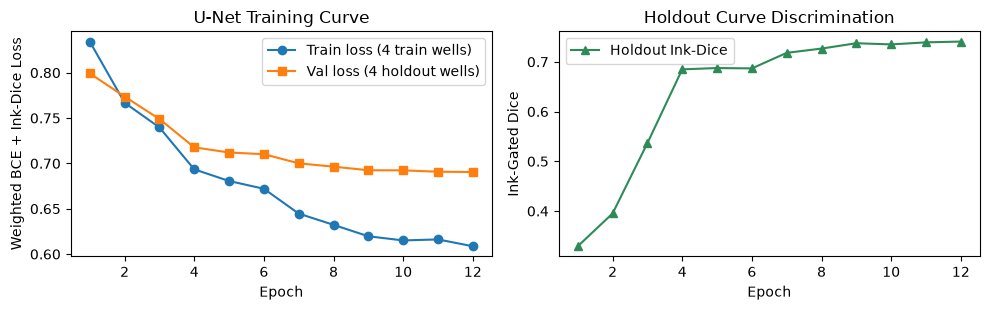

,epoch,train_loss,train_ink_dice,val_loss,val_ink_dice
0,1,0.83432,0.31996,0.79927,0.32926
1,2,0.76689,0.37237,0.77367,0.39520
2,3,0.73963,0.49054,0.74894,0.53661
3,4,0.69344,0.64431,0.71773,0.68492
4,5,0.68060,0.75321,0.71201,0.68747
5,6,0.67202,0.74924,0.71015,0.68680
6,7,0.64465,0.75894,0.70008,0.71805
7,8,0.63226,0.80221,0.69641,0.72664
8,9,0.61963,0.81302,0.69246,0.73737
9,10,0.61508,0.83454,0.69234,0.73500


In [6]:
CKPT_PATH = ROOT / "models" / "kansas_kgs" / "unet.pt"
HIST_PATH = ROOT / "models" / "kansas_kgs" / "training_history.json"

if not CKPT_PATH.exists():
    info = ml_training.train(
        profile="kansas_kgs",
        train_ids=split["train"],
        val_ids=split["holdout"],
        out_dir=ROOT / "models" / "kansas_kgs",
        well_records=records,
        epochs=12,
    )
else:
    hist = json.loads(HIST_PATH.read_text())
    info = {**hist, **hist["train_info"]}

loaded_model, ckpt_meta = ml_models.load_model(CKPT_PATH)
print("Checkpoint loaded:", CKPT_PATH.relative_to(ROOT))
print("Trained strictly on wells:", info["train_wells"])
print("Validated on held-out wells:", info["val_wells"])
print(f"Best val loss: {info['best_val_loss']:.4f} | Best val ink-Dice: {info['best_val_ink_dice']:.4f} | Train time: {info['elapsed_s']:.2f} s")

hist_df = pd.DataFrame(info["epochs"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist_df["epoch"], hist_df["train_loss"], "-o", label="Train loss (4 train wells)")
ax[0].plot(hist_df["epoch"], hist_df["val_loss"], "-s", label="Val loss (4 holdout wells)")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Weighted BCE + Ink-Dice Loss"); ax[0].set_title("U-Net Training Curve"); ax[0].legend()
ax[1].plot(hist_df["epoch"], hist_df["val_ink_dice"], "-^", color="seagreen", label="Holdout Ink-Dice")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Ink-Gated Dice"); ax[1].set_title("Holdout Curve Discrimination"); ax[1].legend()
fig.tight_layout()
plt.show()
hist_df

## 6. Batch-Digitize Held-Out Kansas Wells
Run `ml_batch_digitize.digitize_batch` across all 4 held-out wells (`USA_A_16`, `WEATHERFORD_B_1`, `BACASTOW_1`, `GOHEEN_UNIT_1`).
For each well, the trained U-Net predicts per-pixel curve probabilities, blends them with the conventional cost map (`cost_mode="blend"`), runs the **Rust/Numba DP tracer**, exports `.las` to `outputs/batch/`, computes per-depth confidence, and compares both Conventional and ML traces against the paired KGS LAS.

In [7]:
t0 = time.time()
results = mbd.digitize_batch(
    split["holdout"],
    profile="kansas_kgs",
    out_dir=OUT / "batch",
    model_path=CKPT_PATH,
    cost_mode="blend",
    compare_conventional=True,
    data_root=KGS_ROOT,
)
print(f"Batch digitized {len(results)} held-out wells in {time.time() - t0:.2f} s")

[WARNING] 2026-11-11 05:25:44,354 [RapidOCR] main.py:164: The text detection result is empty


[WARNING] 2026-11-11 05:25:44,477 [RapidOCR] main.py:164: The text detection result is empty


Only engine='normal' can read wrapped files


Batch digitized 4 held-out wells in 497.88 s


## 7. Validate Held-Out Wells Against Paired KGS LAS
Conventional cost map vs U-Net cost map, both traced with the same DP tracer, scored against the paired KGS LAS (r, RMSE).


Mean held-out r   : Conventional = 0.656 -> ML Cost Map = 0.693 (+0.037)
Mean held-out RMSE: Conventional = 30.63 -> ML Cost Map = 28.42 (-2.21 API)


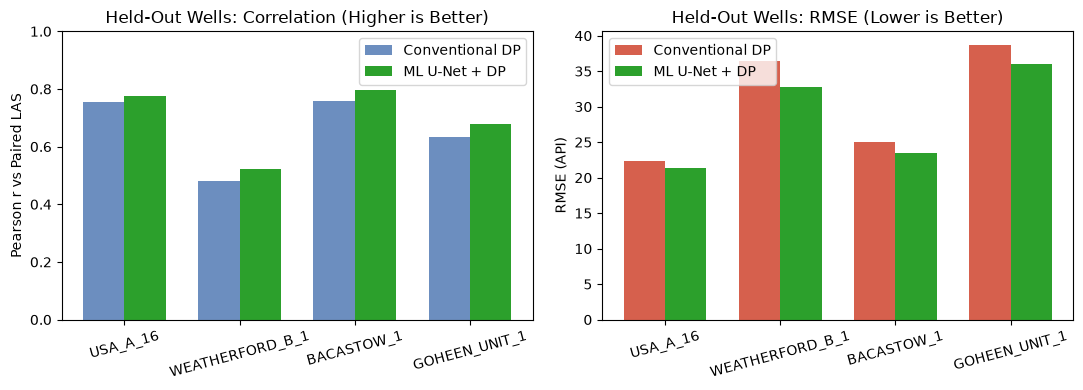

,well,scan,depth_range_ft,r_conv,r_ml,delta_r,rmse_conv,rmse_ml,delta_rmse,mean_conf,p10_conf,flagged_intervals,elapsed_s
0,USA_A_16,4342.tif,1400-7113,0.755,0.776,0.021,22.39,21.36,-1.02,0.934,0.813,75,44.91
1,WEATHERFORD_B_1,194290.tif,1298-4999,0.480,0.522,0.042,36.44,32.80,-3.64,0.890,0.744,91,389.47
2,BACASTOW_1,169724.tif,214-3999,0.757,0.797,0.040,25.02,23.49,-1.52,0.896,0.746,82,52.31
3,GOHEEN_UNIT_1,171203.tif,2211-3700,0.632,0.678,0.045,38.68,36.04,-2.64,0.782,0.345,38,11.00


In [8]:
val_rows = []
for r in results:
    qc_c = r["qc_conventional"]
    qc_m = r["qc_ml"]
    val_rows.append({
        "well": r["well"],
        "scan": r["scan"],
        "depth_range_ft": f"{r['depth_range_ft'][0]:.0f}-{r['depth_range_ft'][1]:.0f}",
        "r_conv": round(qc_c["r"], 3),
        "r_ml": round(qc_m["r"], 3),
        "delta_r": round(qc_m["r"] - qc_c["r"], 3),
        "rmse_conv": round(qc_c["rmse"], 2),
        "rmse_ml": round(qc_m["rmse"], 2),
        "delta_rmse": round(qc_m["rmse"] - qc_c["rmse"], 2),
        "mean_conf": r["mean_conf"],
        "p10_conf": r["p10_conf"],
        "flagged_intervals": r["n_review_intervals"],
        "elapsed_s": r["elapsed_s"],
    })

val_df = pd.DataFrame(val_rows)
val_df.to_csv(QC / "heldout_batch_metrics.csv", index=False)
print("Mean held-out r   : Conventional = %.3f -> ML Cost Map = %.3f (%+.3f)" % (
    val_df["r_conv"].mean(), val_df["r_ml"].mean(), val_df["delta_r"].mean()
))
print("Mean held-out RMSE: Conventional = %.2f -> ML Cost Map = %.2f (%+.2f API)" % (
    val_df["rmse_conv"].mean(), val_df["rmse_ml"].mean(), val_df["delta_rmse"].mean()
))

x = np.arange(len(val_df))
w_bar = 0.36
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].bar(x - w_bar/2, val_df["r_conv"], w_bar, label="Conventional DP", color="#6c8ebf")
axs[0].bar(x + w_bar/2, val_df["r_ml"], w_bar, label="ML U-Net + DP", color="#2ca02c")
axs[0].set_xticks(x); axs[0].set_xticklabels(val_df["well"], rotation=15)
axs[0].set_ylim(0, 1.0); axs[0].set_ylabel("Pearson r vs Paired LAS"); axs[0].set_title("Held-Out Wells: Correlation (Higher is Better)")
axs[0].legend()

axs[1].bar(x - w_bar/2, val_df["rmse_conv"], w_bar, label="Conventional DP", color="#d6604d")
axs[1].bar(x + w_bar/2, val_df["rmse_ml"], w_bar, label="ML U-Net + DP", color="#2ca02c")
axs[1].set_xticks(x); axs[1].set_xticklabels(val_df["well"], rotation=15)
axs[1].set_ylabel("RMSE (API)"); axs[1].set_title("Held-Out Wells: RMSE (Lower is Better)")
axs[1].legend()
fig.tight_layout()
fig.savefig(QC / "heldout_batch_validation.png", dpi=120)
plt.show()
val_df

## 8. Prioritized Review Queue (Low-Confidence Depth Intervals)
`ml_batch_digitize.review_queue` combines DP path dominance confidence with the U-Net's peak probability along the traced path, returning a prioritized list of depth intervals (`mean_conf < 0.78`) where a user anchor click in the web editor will yield the highest value.

In [9]:
queue = mbd.review_queue(results, threshold=0.78, min_len=12, min_span_ft=15.0)
print(f"Total flagged review intervals across 4 held-out wells: {len(queue)}")
pd.DataFrame(queue[:12])

Total flagged review intervals across 4 held-out wells: 16


,well,scan,curve,dp_row_start,dp_row_end,depth_top_ft,depth_base_ft,span_ft,mean_conf,min_conf
0,GOHEEN_UNIT_1,171203.tif,GR,2071,2253,2755.1,2802.7,47.6,0.365,0.329
1,GOHEEN_UNIT_1,171203.tif,GR,4008,4349,3265.1,3354.6,89.5,0.392,0.253
2,GOHEEN_UNIT_1,171203.tif,GR,1975,2063,2729.9,2752.8,22.8,0.398,0.334
3,USA_A_16,4342.tif,GR,34308,34527,7061.0,7098.0,37.0,0.409,0.313
4,GOHEEN_UNIT_1,171203.tif,GR,5212,5284,3582.1,3600.8,18.7,0.425,0.226
5,GOHEEN_UNIT_1,171203.tif,GR,22,92,2216.6,2234.6,18.1,0.430,0.335
6,GOHEEN_UNIT_1,171203.tif,GR,121,292,2242.5,2287.0,44.5,0.440,0.321
7,USA_A_16,4342.tif,GR,301,589,1449.7,1496.8,47.1,0.448,0.225
8,BACASTOW_1,169724.tif,GR,21,113,217.7,232.9,15.3,0.450,0.323
9,USA_A_16,4342.tif,GR,65,276,1410.9,1445.4,34.5,0.452,0.323


## 9. Incremental Fine-Tuning from Saved Corrections
When you review a flagged interval in the app (`pylogdigitizer-app .`) and save the corrected trace for training, it is written under `training_data/corrections/`. Calling `ml_training.fine_tune` updates the U-Net checkpoint on those corrections in a few seconds. (No corrections are shipped; this cell does nothing until you save some.)


In [10]:
CORR_DIR = ROOT / "training_data" / "corrections"
corr_files = [p for p in (mtd.list_corrections(CORR_DIR) if CORR_DIR.exists() else []) if p.name.split("__")[0] in split["train"]]
print(f"Saved correction bundles in {CORR_DIR.relative_to(ROOT)}: {[p.name for p in corr_files]}")
if corr_files:
    ft_info = ml_training.fine_tune(
        base_model=CKPT_PATH,
        corrected_logs=corr_files,
        out_dir=OUT / "models_ft_demo",
        epochs=3,
        lr=5e-4,
    )
    print("Fine-tune summary:", {k: v for k, v in ft_info.items() if k != "epochs"})

Saved correction bundles in training_data/corrections: []
